# MEMBER1 - Handling Missing Data

**Dataset:** Ames Housing (`train.csv`, 1,460 houses, 79 features + `SalePrice`)  
**Task:** predict the sale price of a house (regression).  
Run this notebook from the `notebooks/` folder so the `../data/raw/` paths resolve.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
%matplotlib inline

df = pd.read_csv('../data/raw/train.csv')
test = pd.read_csv('../data/raw/test.csv')
print('train:', df.shape, '| test:', test.shape)
df.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. How much data is missing?

In [2]:
miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_df = pd.DataFrame({'missing': miss, 'percent': (miss / len(df) * 100).round(1),
                        'dtype': df[miss.index].dtypes.astype(str)})
print(len(miss), 'of', df.shape[1], 'columns contain missing values;', int(miss.sum()), 'missing cells in total')
display(miss_df)

19 of 81 columns contain missing values; 7829 missing cells in total


,missing,percent,dtype
PoolQC,1453,99.5,object
MiscFeature,1406,96.3,object
Alley,1369,93.8,object
Fence,1179,80.8,object
MasVnrType,872,59.7,object
FireplaceQu,690,47.3,object
LotFrontage,259,17.7,float64
GarageType,81,5.5,object
GarageYrBlt,81,5.5,float64
GarageFinish,81,5.5,object


## 2. Is the missingness real or structural?

The Ames data description says that for many columns `NA` does **not** mean the value was lost; it means the house *does not have* the feature (no pool, no garage, no basement ...). Check this against the matching size columns.

In [3]:
checks = {
    'PoolQC missing  <-> PoolArea == 0':     (df['PoolQC'].isna(),       df['PoolArea'] == 0),
    'GarageType missing <-> GarageArea == 0': (df['GarageType'].isna(),  df['GarageArea'] == 0),
    'BsmtQual missing <-> TotalBsmtSF == 0': (df['BsmtQual'].isna(),     df['TotalBsmtSF'] == 0),
    'FireplaceQu missing <-> Fireplaces == 0': (df['FireplaceQu'].isna(), df['Fireplaces'] == 0),
    'MasVnrType missing <-> MasVnrArea == 0': (df['MasVnrType'].isna(),  df['MasVnrArea'] == 0),
}
for name, (is_na, is_zero) in checks.items():
    print(f'{name:42s} rows missing: {is_na.sum():4d} | of those with size 0: {(is_na & is_zero).sum():4d}')

PoolQC missing  <-> PoolArea == 0          rows missing: 1453 | of those with size 0: 1453
GarageType missing <-> GarageArea == 0     rows missing:   81 | of those with size 0:   81
BsmtQual missing <-> TotalBsmtSF == 0      rows missing:   37 | of those with size 0:   37
FireplaceQu missing <-> Fireplaces == 0    rows missing:  690 | of those with size 0:  690
MasVnrType missing <-> MasVnrArea == 0     rows missing:  872 | of those with size 0:  859


## 3. Handling strategy

| Case | Columns | Treatment |
|---|---|---|
| Feature absent (structural) | PoolQC, MiscFeature, Alley, Fence, FireplaceQu, Garage*, Bsmt*, MasVnrType | fill with the category **`None`** |
| Numeric size of an absent feature | MasVnrArea | fill with **0** |
| Genuinely unknown numeric | LotFrontage | **median of the same Neighborhood** (street frontage depends on the area) |
| Numeric year of an absent garage | GarageYrBlt | overall median |
| Single unknown category | Electrical (1 row) | most frequent value (mode) |

All fill values must be learned from the **training** data only and re-used for the test file.

In [4]:
df_clean = df.copy()

cat_cols = df.select_dtypes(exclude='number').columns
none_cols = [c for c in cat_cols if df[c].isna().any() and c != 'Electrical']
df_clean[none_cols] = df_clean[none_cols].fillna('None')
df_clean['Electrical'] = df_clean['Electrical'].fillna(df['Electrical'].mode()[0])

df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(0)
df_clean['GarageYrBlt'] = df_clean['GarageYrBlt'].fillna(df['GarageYrBlt'].median())

neigh_median = df.groupby('Neighborhood')['LotFrontage'].median()
global_median = df['LotFrontage'].median()
df_clean['LotFrontage'] = df_clean['LotFrontage'].fillna(df_clean['Neighborhood'].map(neigh_median)).fillna(global_median)

print('Missing cells before:', int(df.isnull().sum().sum()), '| after:', int(df_clean.isnull().sum().sum()))
print('Global LotFrontage median:', global_median)
neigh_median.round(1).sort_values().head(5)

Missing cells before: 7829 | after: 0
Global LotFrontage median: 69.0


Neighborhood
BrDale     21.0
MeadowV    21.0
Blueste    24.0
NPkVill    24.0
Blmngtn    43.0
Name: LotFrontage, dtype: float64

## 4. EDA visualizations

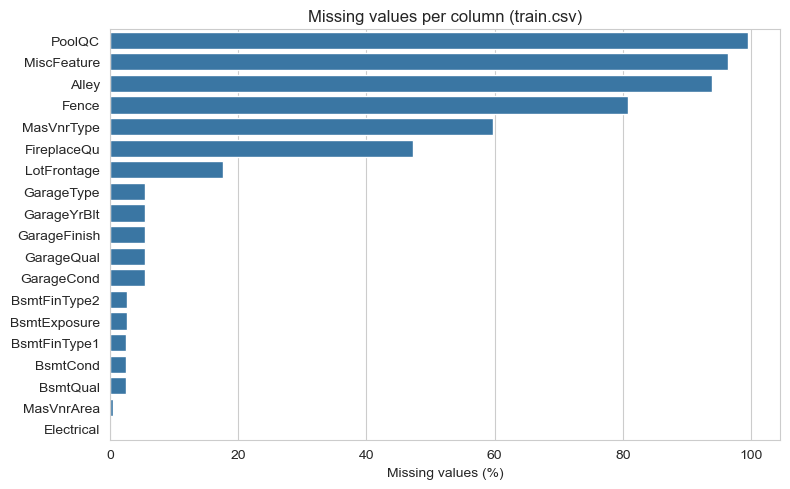

In [5]:
os.makedirs('../results/eda_visualizations/MissingData', exist_ok=True)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=miss_df['percent'], y=miss_df.index, color='#2878B5')
ax.set_xlabel('Missing values (%)'); ax.set_ylabel('')
plt.title('Missing values per column (train.csv)')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/MissingData/missing_values_bar.png', dpi=120)
plt.show()

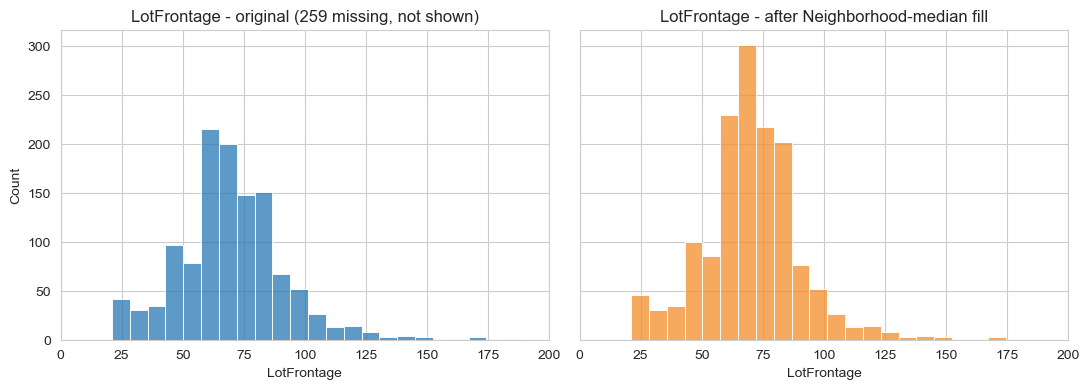

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.histplot(df['LotFrontage'].dropna(), bins=40, ax=axes[0], color='#2878B5')
axes[0].set_title('LotFrontage - original (259 missing, not shown)')
sns.histplot(df_clean['LotFrontage'], bins=40, ax=axes[1], color='#F28E2B')
axes[1].set_title('LotFrontage - after Neighborhood-median fill')
for a in axes: a.set_xlim(0, 200)
plt.tight_layout()
plt.savefig('../results/eda_visualizations/MissingData/lotfrontage_before_after.png', dpi=120)
plt.show()

## 5. Does test.csv have different gaps?

In [7]:
tm = test.isnull().sum(); tm = tm[tm > 0]
new_cols = [c for c in tm.index if df[c].isnull().sum() == 0]
print('Test missing cells:', int(tm.sum()))
print('Columns with gaps in test but NOT in train:', new_cols)
print('-> the imputer must be fitted on train and must also handle columns that were complete in train.')

Test missing cells: 7878
Columns with gaps in test but NOT in train: ['MSZoning', 'Utilities', 'Exterior1st', 'Exterior2nd', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'KitchenQual', 'Functional', 'GarageCars', 'GarageArea', 'SaleType']
-> the imputer must be fitted on train and must also handle columns that were complete in train.


### Interpretation

The training file has **7,829 missing cells in 19 columns**, but most of them are *structural*: PoolQC (99.5 %), MiscFeature, Alley, Fence, FireplaceQu and the Garage/Basement groups are empty because the house has no such feature, and the matching area columns are 0. These were filled with the explicit category `None` (or 0 for areas) rather than deleted, because dropping rows or columns would throw away real information. Only `LotFrontage` (17.7 %) is genuinely unknown; it was filled with the median of the same neighbourhood, which keeps the distribution realistic (see the before/after histogram). The test file has additional gaps in columns that were complete in training, so the final model pipelines use train-fitted imputers (`SimpleImputer`) inside cross-validation to avoid leakage.